In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving red-traffic-light-flat-illustration_1284-22959.avif to red-traffic-light-flat-illustration_1284-22959.avif


Image loaded successfully!
File: red-traffic-light-flat-illustration_1284-22959.avif
Image size: (740, 605)


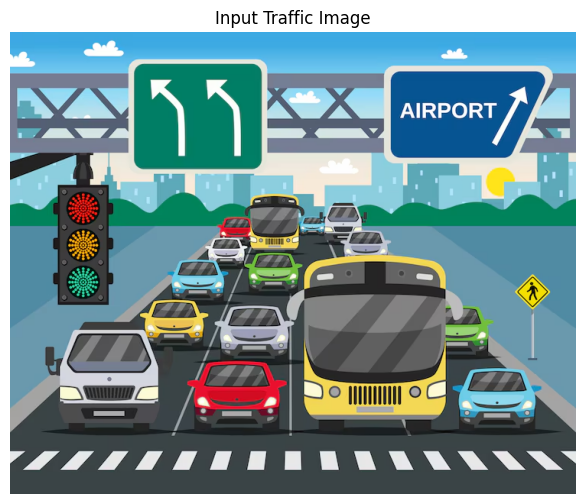

In [ ]:
# STEP 2: LOAD AND DISPLAY THE TRAFFIC IMAGE

!pip install -q pillow matplotlib

from PIL import Image
import matplotlib.pyplot as plt
import os

# Use the uploaded image
image_path = list(uploaded.keys())[0]

# Open AVIF or other supported image formats
image = Image.open(image_path).convert("RGB")

print("Image loaded successfully!")
print("File:", image_path)
print("Image size:", image.size)

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title("Input Traffic Image")
plt.axis("off")
plt.show()

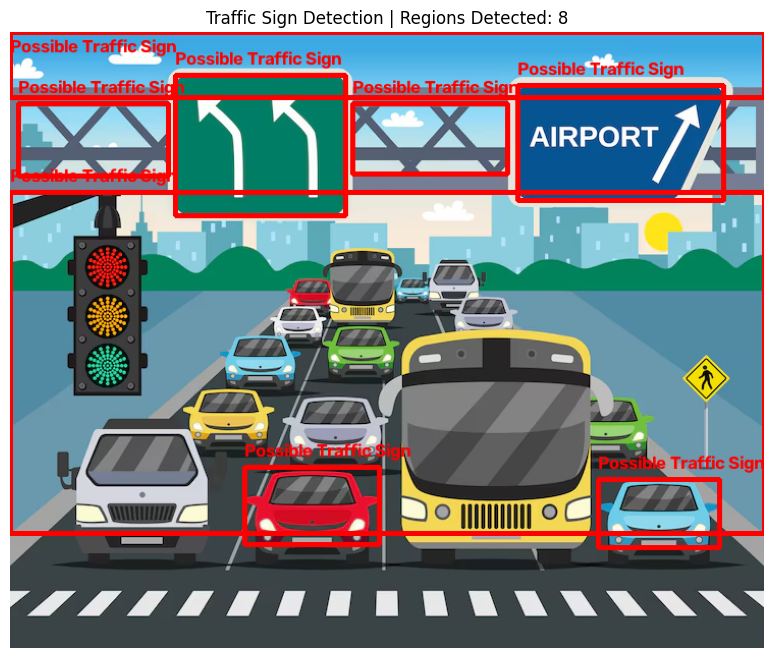

Possible traffic-sign regions detected: 8


In [ ]:
# STEP 3: TRAFFIC SIGN DETECTION

!pip install -q opencv-python-headless matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert image to NumPy array
img = np.array(image)

# Convert RGB to HSV
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

# Detect green, blue and red sign regions
green_mask = cv2.inRange(
    hsv, np.array([35, 60, 40]), np.array([95, 255, 255])
)

blue_mask = cv2.inRange(
    hsv, np.array([90, 60, 40]), np.array([135, 255, 255])
)

red1 = cv2.inRange(
    hsv, np.array([0, 70, 50]), np.array([10, 255, 255])
)

red2 = cv2.inRange(
    hsv, np.array([170, 70, 50]), np.array([180, 255, 255])
)

red_mask = red1 + red2

# Combine color masks
mask = green_mask + blue_mask + red_mask

# Find colored regions
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

result = img.copy()
count = 0

for contour in contours:
    area = cv2.contourArea(contour)

    if area > 3000:
        x, y, w, h = cv2.boundingRect(contour)

        # Draw bounding box
        cv2.rectangle(
            result, (x, y), (x+w, y+h), (255, 0, 0), 3
        )

        cv2.putText(
            result, "Possible Traffic Sign",
            (x, max(y-10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2
        )

        count += 1

# Display simulation output
plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.title(f"Traffic Sign Detection | Regions Detected: {count}")
plt.axis("off")
plt.show()

print("Possible traffic-sign regions detected:", count)